In [90]:
# imports
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [91]:
# getting the data
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

--2026-10-15 19:07:31--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv.1’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.1s    

2026-10-15 19:07:32 (1.78 MB/s) - ‘course_lead_scoring_2026.csv.1’ saved [278746/278746]



In [92]:
df = pd.read_csv("course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [93]:
# checking the columns
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [94]:
# checking the data types
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [95]:
# categorical columns
categorical = list(df.dtypes[df.dtypes == 'str'].index)
categorical

['lead_source', 'industry', 'employment_status', 'location']

In [96]:
# numerical columns
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
numerical

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [97]:
# checking for missing values
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [98]:
# replacing missing categorical values with 'NA'
df[categorical] = df[categorical].fillna('NA')

In [99]:
# replacing missing numerical values with 0
df[numerical] = df[numerical].fillna(0)

In [100]:
# checking for missing values again
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [101]:
# getting statistics summary
df.describe()

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,50508.661000,2.089400,4.472600,0.491304,0.576600
std,24927.396949,1.188987,2.435906,0.202969,0.494147
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,35082.750000,1.000000,3.000000,0.350000,0.000000
50%,52613.000000,2.000000,4.000000,0.490000,1.000000
75%,69752.750000,3.000000,6.000000,0.630000,1.000000
max,109886.000000,6.000000,13.000000,0.990000,1.000000


In [102]:
# getting the mode of the industry column
df['industry'].mode()

0    technology
Name: industry, dtype: str

In [103]:
df.head().T

,0,1,2,3,4
lead_source,organic_search,social_media,referral,paid_ads,referral
industry,technology,technology,retail,manufacturing,manufacturing
employment_status,employed,employed,employed,student,student
location,europe,south_america,europe,NA,north_america
annual_income,88160.0,72688.0,44697.0,0.0,24062.0
number_of_courses_viewed,3,3,3,3,4
interaction_count,4,7,4,6,5
lead_score,0.64,0.72,0.58,0.57,0.62
converted,1,1,1,0,1


In [104]:
# Split the dataset into 80% for training and 20% for testing
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

In [105]:
len(df_full_train), len(df_test)

(4000, 1000)

In [106]:
# Split the remaining training data into 75% for training and 25% for validation.
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

In [107]:
# checking the lengths of the datasets
len(df_full_train), len(df_train), len(df_val), len(df_test)

(4000, 3000, 1000, 1000)

In [108]:
# resetting the index of the datasets
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [109]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [110]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [111]:
df_full_train.reset_index(drop=True, inplace=True)

In [112]:
df_full_train.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [113]:
df_full_train.converted.value_counts(normalize=True)

converted
1    0.57075
0    0.42925
Name: proportion, dtype: float64

In [114]:
df_full_train.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,events,healthcare,employed,south_america,47301.0,5,7,0.69,0
1,organic_search,technology,unemployed,asia,0.0,1,5,0.57,0
2,events,finance,unemployed,asia,47970.0,0,0,0.17,0
3,organic_search,retail,self_employed,south_america,52847.0,3,3,0.45,0
4,paid_ads,finance,employed,africa,73460.0,1,4,0.42,1


In [115]:
# correlation witn converted
df_full_train[numerical].corrwith(df_full_train.converted).sort_values(ascending = False)

lead_score                  0.482078
interaction_count           0.450273
number_of_courses_viewed    0.393200
annual_income               0.188437
dtype: float64

In [116]:
df_full_train[numerical].corr()

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.163680,0.122528,0.222493
number_of_courses_viewed,0.163680,1.000000,0.723040,0.757178
interaction_count,0.122528,0.723040,1.000000,0.916626
lead_score,0.222493,0.757178,0.916626,1.000000


In [117]:
corr = df_full_train[numerical].corr()

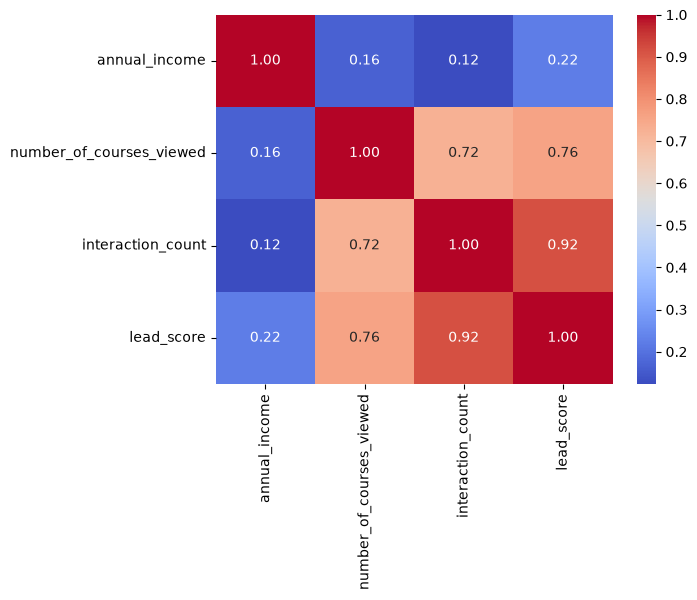

In [118]:
# correlation heatmap
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

In [119]:
from sklearn.metrics import mutual_info_score

In [120]:
def mutual_information_converted(series):
    return mutual_info_score(df_full_train.converted, series)

In [121]:
df_full_train[categorical].apply(mutual_information_converted).sort_values(ascending=False)

lead_source          0.034761
employment_status    0.020313
industry             0.002898
location             0.001050
dtype: float64

In [122]:
from sklearn.feature_extraction import DictVectorizer


In [123]:
features = categorical + numerical
train_dicts = df_train[features].to_dict(orient='records')
val_dicts = df_val[features].to_dict(orient='records')

In [124]:
# One-hot encoding
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [125]:
from sklearn.linear_model import LogisticRegression

In [126]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

In [127]:
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [128]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)

print(round(accuracy, 2))

0.65
